# 04 – SVI calibration and static arbitrage checks

This notebook fits one raw SVI smile to each expiry and checks that the resulting surface is free
of static arbitrage, following Gatheral and Jacquier (2014). We first develop the method on one
expiry (31 March 2027) and then apply it to all expiries.

The output is the file `SPX_2026-10-26_1030_svi.csv`, with the five SVI parameters of each expiry.

### Assumptions

- SPX options are European, so the Black formula on the forward is the correct pricing model.
- Prices are mid quotes, (bid + ask) / 2, taken from one snapshot.
- The forward comes from put-call parity; discount rates come from the US Treasury curve.
- Only out-of-the-money options are used, and expiries shorter than 7 days are removed.
- Dividends are assumed proportional to the index level. This is the condition under which calendar
  arbitrage is equivalent to total variance increasing in $T$ (Gatheral and Jacquier, Lemma 2.1).

## Static arbitrage (Gatheral and Jacquier, 2014, Section 2)

We work with the **total variance** $w(k, T) = \sigma_{\text{imp}}^2(k, T)\, T$ as a function of the
log-moneyness $k = \ln(K/F)$.

**Definition 2.1.** A volatility surface is free of static arbitrage if it is free of calendar spread
arbitrage and each slice is free of butterfly arbitrage.

**Calendar (Lemma 2.1).** With proportional dividends, there is no calendar arbitrage if and only if,
for every $k$,

$$w(k, T_2) \geq w(k, T_1) \qquad \text{whenever } T_2 > T_1.$$

On a plot of $w$ against $k$, the curves of different expiries must never cross.

**Butterfly (Lemma 2.2).** A slice is free of butterfly arbitrage if and only if $g(k) \geq 0$ for
all $k$ and $d_+(k) \to -\infty$ as $k \to +\infty$, where

$$g(k) = \left(1 - \frac{k\,w'}{2w}\right)^2 - \frac{(w')^2}{4}\left(\frac{1}{w} + \frac{1}{4}\right) + \frac{w''}{2},
\qquad d_\pm(k) = -\frac{k}{\sqrt{w}} \pm \frac{\sqrt{w}}{2}.$$

The risk-neutral density of $k$ is (Breeden and Litzenberger, 1978)

$$p(k) = \frac{g(k)}{\sqrt{2\pi w(k)}}\, \exp\left(-\frac{d_-(k)^2}{2}\right),$$

so $g(k) < 0$ means a negative probability, which is impossible.

**Intuition.** A long butterfly $C(K-h) - 2C(K) + C(K+h)$ pays a "tent" at expiry: zero far from
$K$ and positive near $K$, never negative. Its price must therefore be non-negative. In the limit
this means that call prices are convex in the strike, and for a smile written in total variance
Gatheral and Jacquier express the same condition as $g(k) \geq 0$.

**Wings (Lee, 2004).** For large $|k|$ the slope of $w$ must be at most 2.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from functions import svi, svi_g

SNAPSHOT = "SPX_2026-10-26_1030"      # the market snapshot used in the whole project
DATA_DIR = "data"                     # folder with all input and output files

df = pd.read_csv(os.path.join(DATA_DIR, SNAPSHOT + "_iv.csv"))
df["w"] = df["iv"] ** 2 * df["T"]          # total variance of each option
print(df.shape)

(8997, 31)


## 1. Data quality by expiry

Before fitting, we check each expiry. An expiry is accepted when it has:

- at least 20 quotes;
- quotes from $k \leq -0.15$ to $k \geq 0.05$, so that both the put side and the call side are covered;
- a median bid-ask spread below 1 volatility point.

The column `share_no_trade_5d` shows the share of options without a trade in the last five days. It
is reported only as information: Yahoo quotes can be recent even when the last trade is old, so it is
not used as a filter.

In [2]:
snap = pd.to_datetime(df["snapshot_time"], utc=True)
last = pd.to_datetime(df["lastTradeDate"], utc=True)
df["no_trade_5d"] = (snap - last).dt.total_seconds() / 86400 > 5

summary = df.groupby("expiry").agg(
    T=("T", "first"),
    n=("k", "size"),
    k_min=("k", "min"),
    k_max=("k", "max"),
    spread_med=("iv_spread", "median"),
    share_no_trade_5d=("no_trade_5d", "mean"),
)

summary["ok"] = (
    (summary["n"] >= 20)
    & (summary["k_min"] <= -0.15)
    & (summary["k_max"] >= 0.05)
    & (summary["spread_med"] < 0.01)
)

print(summary.round(3))
print("Expiries accepted:", summary["ok"].sum(), "out of", len(summary))
print("Excluded:", summary[~summary["ok"]].index.tolist())

                T    n  k_min  k_max  spread_med  share_no_trade_5d     ok
expiry                                                                    
2026-11-02  0.020  191 -0.390  0.102       0.001              0.005   True
2026-11-03  0.023  191 -0.429  0.113       0.001              0.037   True
2026-11-04  0.025  185 -0.470  0.113       0.002              0.038   True
2026-11-05  0.028  180 -0.513  0.113       0.001              0.028   True
2026-11-06  0.031  259 -0.604  0.113       0.001              0.031   True
2026-11-09  0.039  169 -0.653  0.113       0.001              0.030   True
2026-11-10  0.042  165 -0.653  0.113       0.001              0.085   True
2026-11-11  0.045  162 -0.604  0.136       0.001              0.074   True
2026-11-12  0.047  145 -0.653  0.113       0.001              0.048   True
2026-11-13  0.050  223 -0.704  0.135       0.001              0.018   True
2026-11-16  0.058  131 -0.653  0.135       0.001              0.053   True
2026-11-17  0.061  126 -0

## 2. Development on one expiry: 31 March 2027

We start with the expiry 2027-03-31, which has many quotes and tight bid-ask spreads.

490 quotes


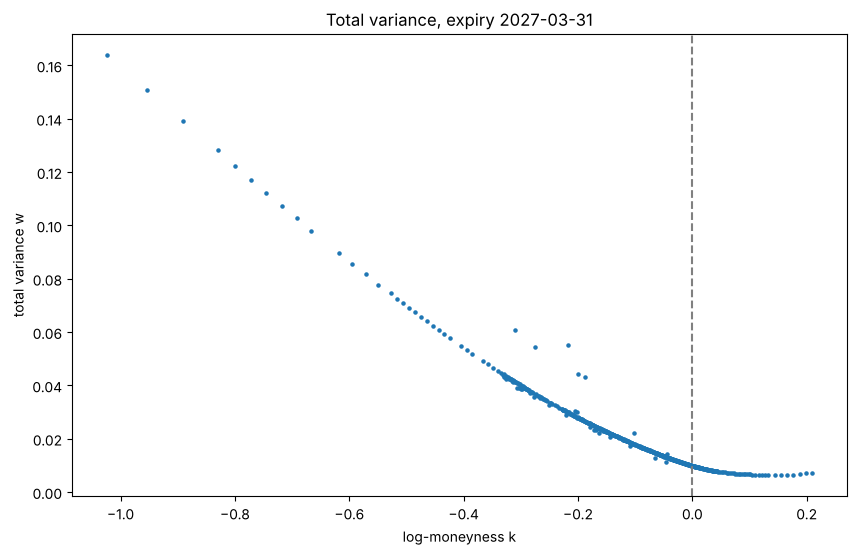

In [3]:
sub = df[df["expiry"] == "2027-03-31"].copy()
sub = sub.sort_values("k").reset_index(drop=True)
print(len(sub), "quotes")

plt.figure(figsize=(10, 6))
plt.scatter(sub["k"], sub["w"], s=5)
plt.axvline(0, color="gray", linestyle="--")      # k = 0: strike equal to the forward
plt.xlabel("log-moneyness k")
plt.ylabel("total variance w")
plt.title("Total variance, expiry 2027-03-31")
plt.show()

### 2.1 Removing stale quotes

Some quotes are far from their neighbours, with last trades several months old. They are not
tradeable prices, and with their small bid-ask spread they would dominate the weighted fit. We
remove a quote when its implied volatility differs by more than one volatility point from the median
of the five quotes around it (the quote and two neighbours on each side).

In [4]:
med = sub["iv"].rolling(5, center=True).median()
sub["keep"] = ~((sub["iv"] - med).abs() > 0.01)

print(sub["keep"].sum(), "quotes kept")
print("Removed strikes:", sub.loc[~sub["keep"], "strike"].tolist())

482 quotes kept
Removed strikes: [5710.0, 5920.0, 6265.0, 6385.0, 6455.0, 7040.0, 7305.0, 7445.0]


### 2.2 The raw SVI function

$$w(k) = a + b\left[\rho\,(k-m) + \sqrt{(k-m)^2 + \sigma^2}\right]$$

Each expiry has its own five parameters (Gatheral and Jacquier, 2014, Section 3.1):

| Parameter | Constraint | Effect on the smile |
|---|---|---|
| $a$ | none, but the minimum of $w$ must be $\geq 0$ | vertical shift: overall level of variance |
| $b$ | $b \geq 0$ | opens or closes both wings |
| $\rho$ | $-1 < \rho < 1$ | rotation: $\rho < 0$ makes the left wing steeper than the right one |
| $m$ | none | horizontal shift of the smile |
| $\sigma$ | $\sigma > 0$ | curvature near the minimum: a small $\sigma$ gives a sharp vertex, a large $\sigma$ a wide, rounded bottom |

**Wings.** For large $|k|$ the curve becomes two straight lines, with slopes
$-b(1-\rho)$ on the left and $b(1+\rho)$ on the right. Lee's moment formula requires both slopes to
be at most 2, that is $b(1+|\rho|) \leq 2$.

**Minimum.** The lowest point of the curve is

$$w_{min} = a + b\,\sigma\sqrt{1-\rho^2} \quad \text{at} \quad k^* = m - \frac{\rho\,\sigma}{\sqrt{1-\rho^2}},$$

so $a$ can be negative as long as $w_{min} \geq 0$.

**These constraints are not enough.** They only make sure that total variance stays positive. A
smile can respect all of them and still have $g(k) < 0$, so butterfly arbitrage must always be
checked after the fit (Section 2.4).

**Non-uniqueness.** Different parameter sets can produce almost the same curve inside the range of
the data and differ only outside it. For this reason we judge a fit by the curve it produces and by
the arbitrage checks, not by the individual parameter values.

The functions `svi` and `svi_g` are defined in `functions.py`.

### 2.3 Weighted least squares fit

We compare model and market in implied volatility. Each error is divided by the bid-ask spread of the
quote, so precise quotes count more than uncertain ones:

$$e_i = \frac{\sigma_{\text{SVI}}(k_i) - \sigma_{\text{market},i}}{\max(\text{spread}_i,\ 0.001)}, \qquad
\sigma_{\text{SVI}}(k) = \sqrt{w_{\text{SVI}}(k) / T}.$$

The floor of 0.001 (0.1 volatility points) prevents a few quotes with an extremely small spread from
receiving an excessive weight. The starting point `x0` was read from the plot of the data.

In [5]:
good = sub[sub["keep"]].copy()
good["spread_fit"] = np.maximum(good["iv_spread"], 0.001)
T = good["T"].iloc[0]

def residuals(params):
    w_svi = svi(good["k"].values, *params)
    iv_svi = np.sqrt(np.maximum(w_svi, 1e-10) / T)          # from total variance to volatility
    return (iv_svi - good["iv"].values) / good["spread_fit"].values

x0 = [-0.007, 0.087, -0.67, -0.01, 0.2]            # starting point (a, b, rho, m, sig)
lower = [-1, 0, -0.999, -0.5, 0.001]
upper = [1, 2, 0.999, 0.5, 2]

params = least_squares(residuals, x0, bounds=(lower, upper)).x
print("a, b, rho, m, sig:", np.round(params, 4))

iv_fit = np.sqrt(svi(good["k"].values, *params) / T)
err = (iv_fit - good["iv"].values) * 100                    # error in volatility points
print("RMSE (vol points):", round(np.sqrt(np.mean(err**2)), 3))
print("Max error (vol points):", round(np.abs(err).max(), 3))

a, b, rho, m, sig: [-0.2031  0.5358  0.6053  0.5     0.4906]
RMSE (vol points): 0.198
Max error (vol points): 0.919


The fit is very close to the quotes, but the parameters are unusual: $m$ stops exactly at its upper
bound (0.5) and $\rho$ is positive, while an equity skew normally has $\rho < 0$. Inside the data
range many parameter sets give almost the same curve, so the optimizer has found one that fits the
quotes well but behaves badly outside them. The next sections show the consequence.

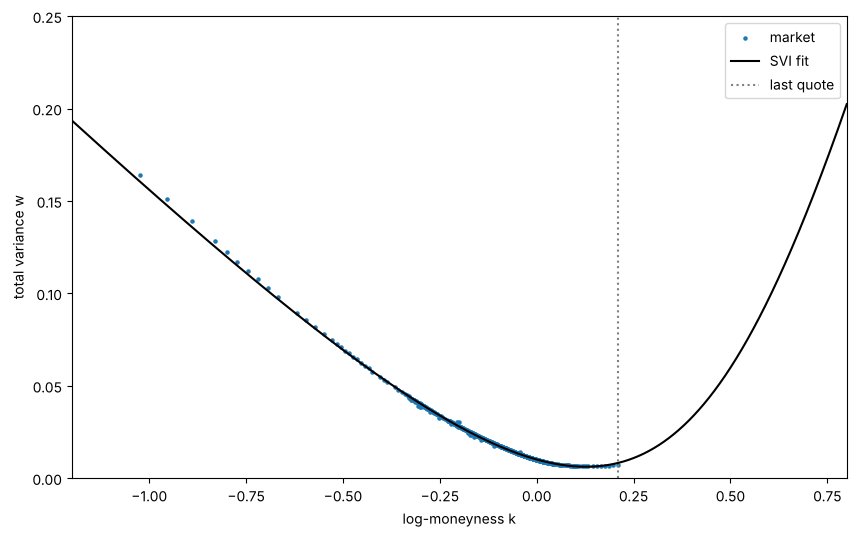

In [6]:
k_wide = np.linspace(-3, 2, 5001)        # wide grid, also outside the quoted strikes

plt.figure(figsize=(10, 6))
plt.scatter(good["k"], good["w"], s=5, label="market")
plt.plot(k_wide, svi(k_wide, *params), color="black", label="SVI fit")
plt.axvline(good["k"].max(), color="gray", linestyle=":", label="last quote")
plt.xlim(-1.2, 0.8)
plt.ylim(0, 0.25)
plt.xlabel("log-moneyness k")
plt.ylabel("total variance w")
plt.legend()
plt.show()

### 2.4 Butterfly check with $g(k)$

Two tests of the function `svi_g`:

1. a flat smile ($b = 0$) must give $g = 1$ everywhere;
2. the example of Vogt (Gatheral and Jacquier, Example 3.1) respects all the parameter constraints
   but must give a negative $g$, with a minimum of about $-0.033$ near $k = 0.88$.

Flat smile: min g = 1.0  max g = 1.0
Vogt: min g = -0.0329 at k = 0.879


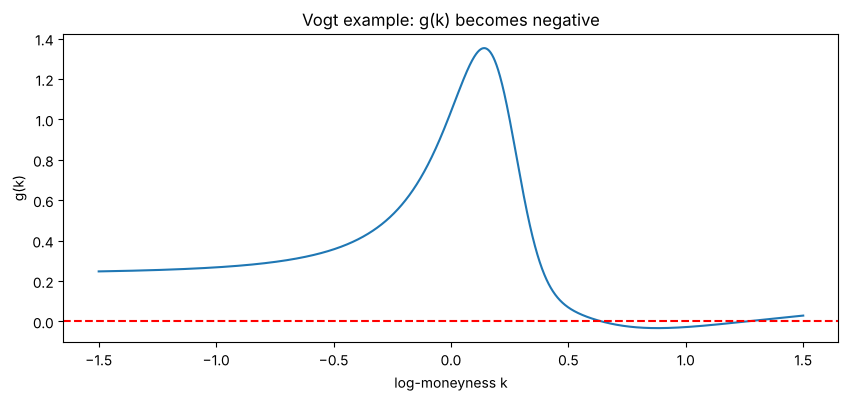

In [7]:
k_test = np.linspace(-1.5, 1.5, 3001)

g_flat = svi_g(k_test, 0.02, 0, 0, 0, 0.1)
print("Flat smile: min g =", g_flat.min(), " max g =", g_flat.max())

g_vogt = svi_g(k_test, -0.0410, 0.1331, 0.3060, 0.3586, 0.4153)     # order: a, b, rho, m, sig
print("Vogt: min g =", round(g_vogt.min(), 4), "at k =", round(k_test[g_vogt.argmin()], 3))

plt.figure(figsize=(10, 4))
plt.plot(k_test, g_vogt)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("log-moneyness k")
plt.ylabel("g(k)")
plt.title("Vogt example: g(k) becomes negative")
plt.show()

Now we apply the same check to our fit, on the wide grid of $k$.

Our fit: min g = -0.2337 at k = 1.159


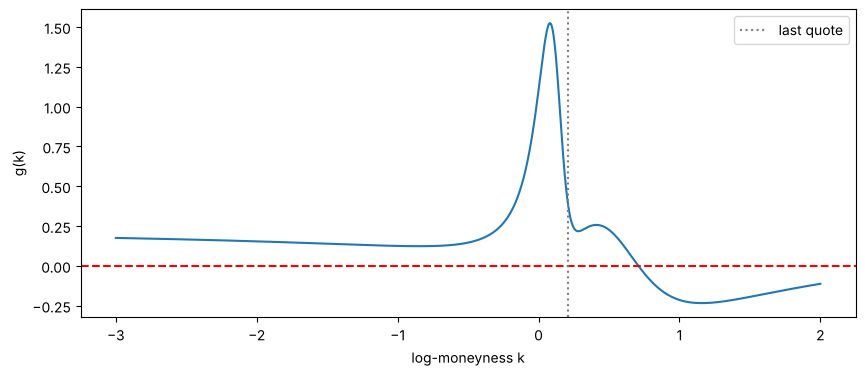

In [8]:
g_fit = svi_g(k_wide, *params)
print("Our fit: min g =", round(g_fit.min(), 4), "at k =", round(k_wide[g_fit.argmin()], 3))

plt.figure(figsize=(10, 4))
plt.plot(k_wide, g_fit)
plt.axhline(0, color="red", linestyle="--")
plt.axvline(good["k"].max(), color="gray", linestyle=":", label="last quote")
plt.xlabel("log-moneyness k")
plt.ylabel("g(k)")
plt.legend()
plt.show()

### 2.5 Calibration with a butterfly penalty

The unconstrained fit is very close to the quotes, but $g(k)$ becomes negative beyond the last quote,
so the extrapolated call wing implies negative probabilities. Following the idea of Gatheral and
Jacquier (2014, Section 5), we repeat the calibration and add a penalty for every point of the wide
grid where $g$ is too small:

$$\min_{a,b,\rho,m,\sigma} \left[ \sum_i e_i^2 + \lambda^2 \sum_j \min\big(g(k_j) - \varepsilon,\ 0\big)^2 \right],
\qquad \lambda = 10^4,\ \ \varepsilon = 0.001.$$

The penalty is zero where $g(k_j) \geq \varepsilon$ and very large otherwise. The small margin
$\varepsilon$ is needed because a penalty does not impose the condition exactly: without it, the
optimizer stops at values of $g$ slightly below zero (about $-10^{-5}$). With the margin, $g$ stays
strictly positive after the optimization. The optimizer accepts a curve that is a little less close
to the quotes but free of butterfly arbitrage everywhere.

In [9]:
k_pen = np.linspace(-3, 2, 1001)      # grid where g is checked during the fit
lam = 1e4                             # weight of the penalty
eps = 0.001                           # safety margin on g

def residuals_pen(params):
    err_data = residuals(params)                              # errors on the quotes
    err_arb = lam * np.minimum(svi_g(k_pen, *params) - eps, 0)  # 0 where g >= eps, large where g < eps
    return np.concatenate([err_data, err_arb])

params_pen = least_squares(residuals_pen, x0, bounds=(lower, upper)).x
print("a, b, rho, m, sig:", np.round(params_pen, 4))

iv_fit_pen = np.sqrt(svi(good["k"].values, *params_pen) / T)
err_pen = (iv_fit_pen - good["iv"].values) * 100
print("RMSE (vol points):", round(np.sqrt(np.mean(err_pen**2)), 3))
print("Max error (vol points):", round(np.abs(err_pen).max(), 3))

a, b, rho, m, sig = params_pen
g_pen = svi_g(k_wide, *params_pen)
print("min g:", round(g_pen.min(), 5))
print("min w:", round(a + b * sig * np.sqrt(1 - rho**2), 5))
print("Lee: b(1+|rho|) =", round(b * (1 + abs(rho)), 3))
print("Butterfly-free:", g_pen.min() > 0)

a, b, rho, m, sig: [-0.0435  0.1431 -0.2153  0.0635  0.3547]
RMSE (vol points): 0.276
Max error (vol points): 1.947
min g: 0.00098
min w: 0.00613
Lee: b(1+|rho|) = 0.174
Butterfly-free: True


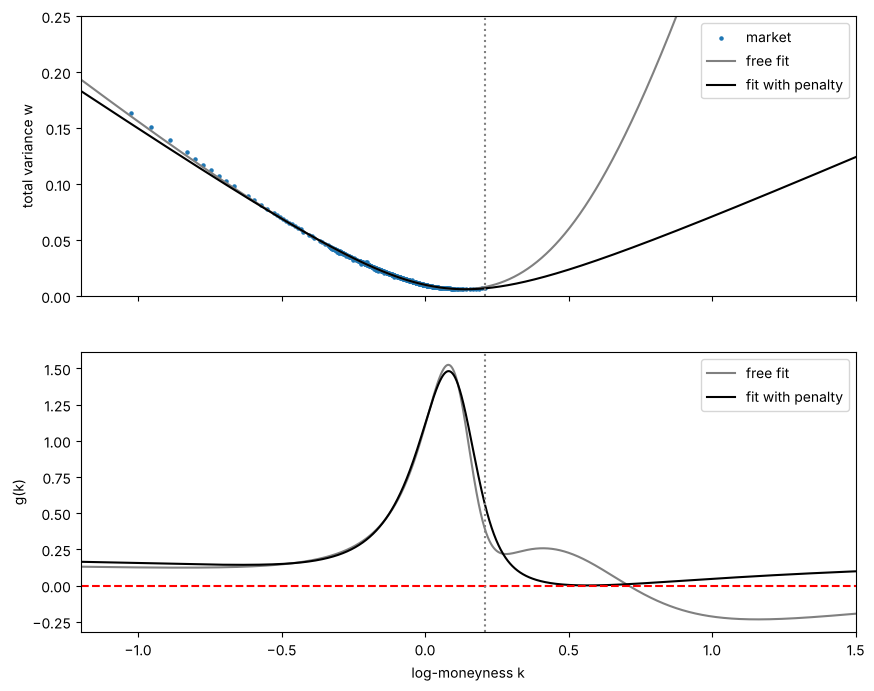

In [10]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

ax1.scatter(good["k"], good["w"], s=5, label="market")
ax1.plot(k_wide, svi(k_wide, *params), color="gray", label="free fit")
ax1.plot(k_wide, svi(k_wide, *params_pen), color="black", label="fit with penalty")
ax1.axvline(good["k"].max(), color="gray", linestyle=":")
ax1.set_ylabel("total variance w")
ax1.set_ylim(0, 0.25)
ax1.legend()

ax2.plot(k_wide, svi_g(k_wide, *params), color="gray", label="free fit")
ax2.plot(k_wide, svi_g(k_wide, *params_pen), color="black", label="fit with penalty")
ax2.axhline(0, color="red", linestyle="--")
ax2.axvline(good["k"].max(), color="gray", linestyle=":")
ax2.set_xlabel("log-moneyness k")
ax2.set_ylabel("g(k)")
ax2.legend()

plt.xlim(-1.2, 1.5)
plt.show()

**Result.** With the penalty, the RMSE rises from 0.20 to 0.28 volatility points and the maximum
error from 0.92 to 1.95. Almost all of this cost is in the far put wing ($k < -0.6$, 11 quotes),
where quotes are less precise; near the money the error grows only from 0.17 to 0.19 points, and on
the call side it even falls. In exchange, the parameters become typical of an equity smile
($\rho = -0.22$, $m = 0.06$), $g$ stays above 0.00098 on the whole grid from $k = -3$ to $k = 2$, the
minimum total variance is positive (0.0061) and the wing slope (0.17) is far below Lee's bound of 2.

## 3. Calibration of all expiries

We now repeat the same procedure for every accepted expiry. The function `fit_expiry` contains all
the steps of Section 2:

1. **stale-quote filter**: the rolling median of five quotes, with a threshold of one volatility point;
2. **weighted least squares** on implied volatility, with the bid-ask spread as weight (floor 0.001);
3. **butterfly penalty** on $g(k) - \varepsilon$, on the grid $-3 \leq k \leq 2$;
4. **starting point adapted to the expiry**: total variance grows with maturity, so one fixed
   starting point does not suit all expiries. We start from $a = 0.5\, w_{ATM}$, where $w_{ATM}$ is
   the market total variance interpolated at $k = 0$, and from neutral values for the other
   parameters.

After the fit, the function returns the parameters and the quality checks: RMSE and maximum error in
volatility points, the minimum of $g$ on the wide grid, and Lee's wing slope $b(1+|\rho|)$.

In [11]:
# settings of the calibration, all in one place
k_pen = np.linspace(-3, 2, 1001)      # grid for the penalty
k_wide = np.linspace(-3, 2, 5001)     # grid for the final check of g
lam = 1e4
eps = 0.001
lower = [-1, 0, -0.999, -0.5, 0.001]
upper = [1, 2, 0.999, 0.5, 2]

def fit_expiry(expiry):
    # 1. quotes of the expiry, sorted by k, without stale quotes
    sub = df[df["expiry"] == expiry].sort_values("k").reset_index(drop=True)
    med = sub["iv"].rolling(5, center=True).median()
    good = sub[~((sub["iv"] - med).abs() > 0.01)]

    T = good["T"].iloc[0]
    k = good["k"].values
    iv = good["iv"].values
    spread = np.maximum(good["iv_spread"].values, 0.001)

    # 2. errors on the quotes + butterfly penalty
    def residuals_pen(params):
        iv_svi = np.sqrt(np.maximum(svi(k, *params), 1e-10) / T)
        err_data = (iv_svi - iv) / spread
        err_arb = lam * np.minimum(svi_g(k_pen, *params) - eps, 0)
        return np.concatenate([err_data, err_arb])

    # 3. starting point from the ATM total variance
    w_atm = np.interp(0, k, good["w"].values)
    x0 = [0.5 * w_atm, 0.1, -0.5, 0.0, 0.1]

    p = least_squares(residuals_pen, x0, bounds=(lower, upper)).x

    # 4. quality and checks
    err = (np.sqrt(np.maximum(svi(k, *p), 1e-10) / T) - iv) * 100
    return {
        "expiry": expiry, "T": T, "n": len(good),
        "a": p[0], "b": p[1], "rho": p[2], "m": p[3], "sig": p[4],
        "rmse": np.sqrt(np.mean(err**2)),
        "max_err": np.abs(err).max(),
        "g_min": svi_g(k_wide, *p).min(),
        "lee": p[1] * (1 + abs(p[2])),
    }

In [12]:
rows = []
for expiry in summary[summary["ok"]].index:
    rows.append(fit_expiry(expiry))

fits = pd.DataFrame(rows).set_index("expiry").sort_values("T")
print(fits.round(4))
print(fits[["rmse", "max_err", "g_min", "lee"]].describe().round(4))

                 T    n       a       b     rho       m     sig    rmse  \
expiry                                                                    
2026-11-02  0.0199  191 -0.0107  0.0507 -0.4014 -0.0672  0.2354  1.5191   
2026-11-03  0.0227  191 -0.0101  0.0501 -0.4014 -0.0595  0.2269  1.4875   
2026-11-04  0.0254  185 -0.0099  0.0493 -0.3709 -0.0449  0.2241  1.1288   
2026-11-05  0.0281  180 -0.0094  0.0487 -0.3649 -0.0378  0.2170  1.0603   
2026-11-06  0.0309  259 -0.0102  0.0514 -0.3060 -0.0246  0.2181  0.8613   
2026-11-09  0.0391  169 -0.0095  0.0508 -0.3044 -0.0174  0.2063  0.7605   
2026-11-10  0.0418  165 -0.0095  0.0518 -0.2704 -0.0080  0.2021  0.6670   
2026-11-11  0.0446  162 -0.0091  0.0520 -0.2496 -0.0010  0.1934  0.6558   
2026-11-12  0.0473  145 -0.0097  0.0541 -0.2528 -0.0013  0.1974  0.5725   
2026-11-13  0.0501  223 -0.0099  0.0559 -0.2286  0.0037  0.1944  0.5213   
2026-11-16  0.0583  131 -0.0095  0.0562 -0.2140  0.0092  0.1866  0.5943   
2026-11-17  0.0610  126 -

In [13]:
param_cols = ["a", "b", "rho", "m", "sig"]
print("Expiries fitted:", len(fits))
print("All slices butterfly-free (g > 0):", (fits["g_min"] > 0).all())
print("All slices respect Lee (b(1+|rho|) <= 2):", (fits["lee"] <= 2).all())
print("Wing slope from", round(fits["lee"].min(), 3), "to", round(fits["lee"].max(), 3))

groups = pd.cut(fits["T"], [0, 0.1, 0.5, 2.2, 6], labels=["< 5 weeks", "5 weeks - 6 months", "6 months - 2 years", "> 2 years"])
print(fits.groupby(groups, observed=True)["rmse"].agg(["count", "median", "max"]).round(3))

Expiries fitted: 47
All slices butterfly-free (g > 0): True
All slices respect Lee (b(1+|rho|) <= 2): True
Wing slope from 0.065 to 0.335
                    count  median    max
T                                       
< 5 weeks              21   0.656  1.519
5 weeks - 6 months     12   0.343  0.761
6 months - 2 years     13   0.379  0.665
> 2 years               1   0.828  0.828


**Result.** All 47 accepted expiries are free of butterfly arbitrage ($g \geq 0.001$ on the wide grid)
and respect Lee's bound, with wing slopes between 0.07 and 0.34. The median RMSE is 0.54 volatility
points. Errors are largest for expiries shorter than 5 weeks (median RMSE 0.66, up to 1.52), whose
smiles are very steep and hard to describe with five parameters, and smaller between 5 weeks and
2 years (median 0.34–0.38). The RMSE of each expiry includes the far wings; notebook 05 measures the
error in the region used for hedging, where it is much smaller.

## 4. Calendar check

The butterfly check works on one expiry at a time. The calendar condition compares different
expiries: for every $k$, total variance must not decrease with maturity,

$$w(k, T_2) \geq w(k, T_1) \qquad \text{whenever } T_2 > T_1.$$

The condition is on total variance, not on implied volatility: volatility can fall with maturity,
but $w = \sigma^2 T$ cannot.

For each pair of consecutive expiries we evaluate both SVI curves on the same grid of $k$ and look
for negative values of $w(k, T_{i+1}) - w(k, T_i)$. The result depends on where we look, so we run
four checks:

| Check | Expiries | Grid of $k$ | Question |
|---|---|---|---|
| A | all | $-0.5$ to $0.2$, only where both expiries have quotes | Is the surface consistent where it is fixed by data? |
| B | 6 months to 2 years | $-0.65$ to $0.1$ | Is it consistent where the hedges are priced? |
| C | 6 months to 2 years | as B, only where both expiries have quotes | Same as B, data range only |
| D | 6 months to 2 years | $-1.0$ to $0.3$ | What happens in the extrapolated wings? |

If curves cross, Gatheral and Jacquier (2014, Section 5.2) measure the size of the crossing
("crossedness", Definition 5.1) and calibrate the expiries in order with a penalty against crossing.
We first measure how many pairs cross and by how much, and then decide whether this is needed.

In [14]:
k_range = df.groupby("expiry")["k"].agg(["min", "max"])      # quoted range of each expiry

def check_calendar(k_lo, k_hi, common=False, T_min=0, T_max=99):
    pairs = 0
    crossings = []
    for i in range(len(fits) - 1):
        e1, e2 = fits.index[i], fits.index[i + 1]
        if fits.loc[e1, "T"] < T_min or fits.loc[e2, "T"] > T_max:
            continue                                     # pair outside the maturity range
        pairs += 1
        lo, hi = k_lo, k_hi
        if common:                                       # only where both expiries have quotes
            lo = max(k_range.loc[e1, "min"], k_range.loc[e2, "min"], k_lo)
            hi = min(k_range.loc[e1, "max"], k_range.loc[e2, "max"], k_hi)
        k_cal = np.linspace(lo, hi, 501)
        diff = svi(k_cal, *fits.loc[e2, param_cols]) - svi(k_cal, *fits.loc[e1, param_cols])
        if diff.min() < 0:
            crossings.append((e1, e2, round(diff.min(), 6), round(k_cal[diff.argmin()], 3)))
    print(f"Pairs checked: {pairs}, crossings: {len(crossings)}")
    for c in crossings:
        print("   ", c)

print("A"); check_calendar(-0.5, 0.2, common=True)
print("B"); check_calendar(-0.65, 0.1, T_min=0.5, T_max=2.2)
print("C"); check_calendar(-0.65, 0.1, common=True, T_min=0.5, T_max=2.2)
print("D"); check_calendar(-1.0, 0.3, T_min=0.5, T_max=2.2)

A
Pairs checked: 46, crossings: 3
    ('2026-11-20', '2026-11-23', np.float64(-3.3e-05), np.float64(0.135))
    ('2026-11-30', '2026-12-01', np.float64(-7.5e-05), np.float64(0.134))
    ('2027-03-19', '2027-03-31', np.float64(-2.3e-05), np.float64(0.2))
B
Pairs checked: 12, crossings: 0
C
Pairs checked: 12, crossings: 0
D
Pairs checked: 12, crossings: 5
    ('2027-06-17', '2027-06-30', np.float64(-0.001423), np.float64(-1.0))
    ('2027-06-30', '2027-07-16', np.float64(-0.001117), np.float64(0.3))
    ('2027-09-17', '2027-09-30', np.float64(-0.003538), np.float64(-1.0))
    ('2027-09-30', '2027-10-15', np.float64(-0.001636), np.float64(0.3))
    ('2027-12-17', '2028-01-21', np.float64(-0.001458), np.float64(-1.0))


**Result.**

- **A:** 3 crossings out of 46 pairs. They are very small (at most $7.5 \cdot 10^{-5}$ in total
  variance), between expiries only a few days apart, at the end of the call side ($k \approx 0.13$–$0.2$).
- **B and C:** no crossings for the 12 pairs between 6 months and 2 years, so the region of the hedges
  is free of calendar arbitrage.
- **D:** 5 crossings, all at the edges of the grid ($k = -1$ or $k = 0.3$). Four of them involve an
  end-of-quarter expiry (June 2027, September 2027) whose quotes stop near $k = -0.9$ and $k = 0.2$,
  so the crossing is in its extrapolated part. The fifth (December 2027 and January 2028 at $k = -1$)
  corresponds to a difference of about 0.15 volatility points.

**Conclusion.** The surface is free of static arbitrage in the region where it is used. The small
crossings elsewhere are below the precision of the quotes, so we do not add the crossedness penalty
of Gatheral and Jacquier. It would be needed for products that depend on the deep wings, for example
strikes below $k = -0.65$ at maturities above 6 months.

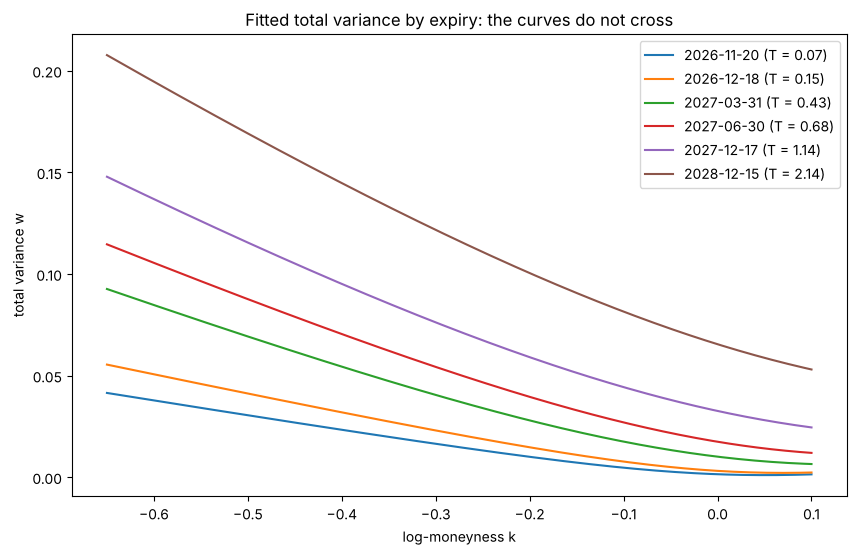

In [15]:
selected = ["2026-11-20", "2026-12-18", "2027-03-31", "2027-06-30", "2027-12-17", "2028-12-15"]
selected = [e for e in selected if e in fits.index]   # keep only calibrated expiries
k_plot = np.linspace(-0.65, 0.1, 300)          # region of the hedges

plt.figure(figsize=(10, 6))
for e in selected:
    plt.plot(k_plot, svi(k_plot, *fits.loc[e, param_cols]), label=f"{e} (T = {fits.loc[e, 'T']:.2f})")
plt.xlabel("log-moneyness k")
plt.ylabel("total variance w")
plt.title("Fitted total variance by expiry: the curves do not cross")
plt.legend()
plt.show()

## 5. The implied volatility surface

We plot the fitted implied volatility $\sigma = \sqrt{w/T}$ for $-0.6 \leq k \leq 0.2$ and all
calibrated expiries, and then the term structure of volatility at fixed log-moneyness.

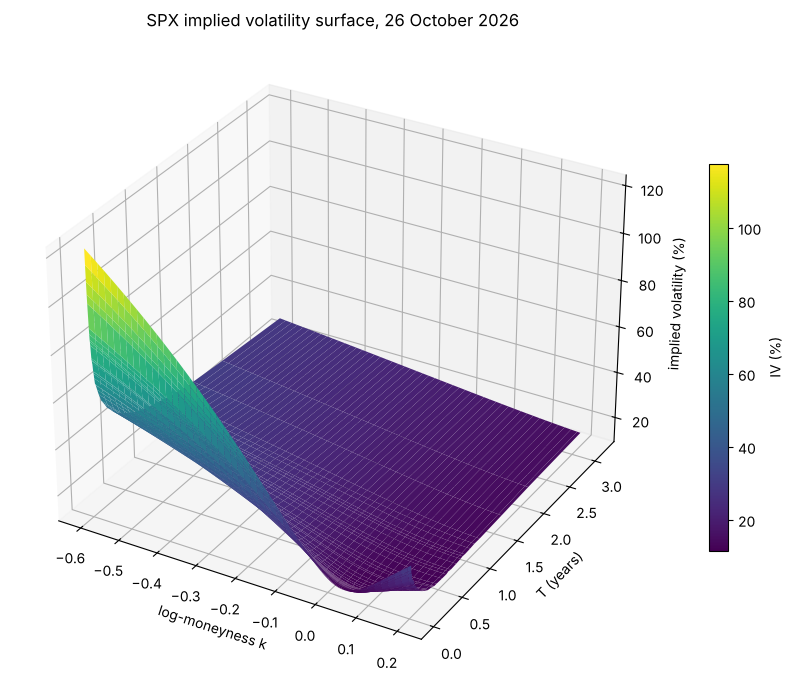

In [16]:
k_surf = np.linspace(-0.6, 0.2, 100)
T_list = fits["T"].values
K_grid, T_grid = np.meshgrid(k_surf, T_list)
iv_grid = np.zeros_like(K_grid)

for i, (e, row) in enumerate(fits.iterrows()):
    w = svi(k_surf, *row[param_cols])
    if np.any(w <= 0):
        raise ValueError(f"Non-positive total variance for {e}")
    iv_grid[i, :] = np.sqrt(w / row["T"])

fig = plt.figure(figsize=(11, 7))
ax = fig.add_subplot(projection="3d")
surf = ax.plot_surface(K_grid, T_grid, iv_grid * 100, cmap="viridis", edgecolor="none")
ax.set_xlabel("log-moneyness k")
ax.set_ylabel("T (years)")
ax.set_zlabel("implied volatility (%)")
ax.set_title("SPX implied volatility surface, 26 October 2026")
fig.colorbar(surf, ax=ax, shrink=0.6, label="IV (%)")
plt.tight_layout()
plt.show()

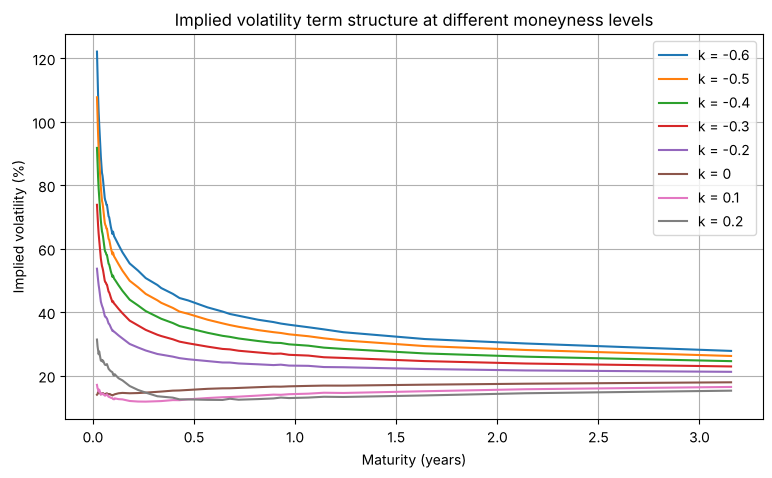

In [17]:
plt.figure(figsize=(9, 5))
for k in [-0.6, -0.5, -0.4, -0.3, -0.2, 0, 0.1, 0.2]:
    iv_values = []
    for _, row in fits.iterrows():
        iv_values.append(np.sqrt(svi(k, *row[param_cols]) / row["T"]) * 100)
    plt.plot(fits["T"], iv_values, label=f"k = {k}")
plt.xlabel("Maturity (years)")
plt.ylabel("Implied volatility (%)")
plt.title("Implied volatility term structure at different moneyness levels")
plt.legend()
plt.grid()
plt.show()

## 6. Saving the surface

The parameters and the quality checks of each expiry are saved for the pricer (notebook 05).

In [18]:
out_path = os.path.join(DATA_DIR, SNAPSHOT + "_svi.csv")
fits.to_csv(out_path)
print("Saved:", out_path, fits.shape)

Saved: data/SPX_2026-10-26_1030_svi.csv (47, 11)
